<div dir="rtl" style="text-align:right">

# نوت‌بوک ۰۱ — شناخت داده (EDA)

هدف این نوت‌بوک این است که **قبل از ساختن هر مدل** بدانیم داده چه می‌گوید: آیا سالم و هم‌تراز است، نشت چه سهمی از زمان را می‌گیرد، رفتار عادی فشار چقدر ثابت است، نویز چه ساختاری دارد، جریان‌ها و AMR چه اطلاعاتی اضافه می‌کنند و اثر نشت در داده خام چگونه دیده می‌شود. هر یافته به یک تصمیم طراحی گره می‌خورد (تفکیک داده، پنجره، خط پایه، وزن‌دهی، داده مصنوعی) و در پایان در `artifacts/eda_summary.json` ذخیره می‌شود تا در گزارش و نوت‌بوک‌های بعدی تکرار نشود.

این نوت‌بوک **هیچ مدلی آموزش نمی‌دهد** و فقط از `historical_2018/` می‌خواند؛ به `leaklib` و خروجی‌های بخش ۱ نیازی ندارد. ستون‌های موردنیاز: `pressures_m`، `flows_m3h`، `levels_m`، `demands_Lh`، `labels`، `leaks` و `leak_flows_m3h`.

| بخش | محتوا | تصمیمی که تغذیه می‌کند |
| --- | --- | --- |
| ۱ | بارگذاری، هم‌ترازی زمانی، مقادیر گمشده، واحدها، حسگر یخ‌زده و جهش | کیفیت داده و پیش‌پردازش |
| ۲ | برچسب‌ها و نشت‌ها: سهم زمان نشت، همپوشانی، بازه‌های بدون نشت | تفکیک داده، وزن‌دهی، داده مصنوعی |
| ۳ | رفتار عادی فشار، ساختار نویز، خودهمبستگی | خط پایه، سفیدسازی، قاعده تفکیک |
| ۴ | جریان، تراز مخزن و AMR؛ برآورد سهم جریان‌ها | کانال‌های ورودی، `FLOW_SHARE` |
| ۵ | اثر نشت در داده واقعی | پنجره، آستانه، فرض مدل هیدرولیکی |
| ۶ | خلاصه یافته‌ها | گزارش |

برچسب نمودارها انگلیسی و همه نمودارها در `figures/` ذخیره می‌شوند.

</div>

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA, ART, FIG = ROOT / 'historical_2018', ROOT / 'artifacts', ROOT / 'figures'
ART.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.grid': True, 'grid.alpha': .25})
pd.set_option('display.width', 200)
STEP = 12                                  # 5-minute steps per hour
TRAIN_END = pd.Timestamp('2018-09-09')     # split date used in the part-2 scripts (only for descriptive statistics here)
SUMMARY = {}                               # numbers collected for the report


def savefig(name):
    plt.gcf().savefig(FIG / f'{name}.png', bbox_inches='tight')


def read(name):
    return pd.read_csv(DATA / name, index_col=0, parse_dates=True)


P, Fl, Lv, Dm = read('pressures_m.csv'), read('flows_m3h.csv'), read('levels_m.csv'), read('demands_Lh.csv')
lab, LF = read('labels.csv'), read('leak_flows_m3h.csv')
leaks = pd.read_csv(DATA / 'leaks.csv', parse_dates=['start', 'peak', 'end'])
print({n: d.shape for n, d in dict(pressures=P, flows=Fl, levels=Lv, amr=Dm, labels=lab, leak_flows=LF, leaks=leaks).items()})

{'pressures': (105120, 33), 'flows': (105120, 3), 'levels': (105120, 1), 'amr': (105120, 82), 'labels': (105120, 3), 'leak_flows': (105120, 20), 'leaks': (20, 8)}


<div dir="rtl" style="text-align:right">

## ۱. صحت و هم‌ترازی داده

بررسی‌ها: همه جدول‌ها شاخص زمانی یکسان و گام ۵ دقیقه دارند؛ مقدار گمشده و شاخص تکراری ندارند؛ واحدها معقولند؛ حسگر یخ‌زده (مقدار ثابت طولانی) یا جهش ناگهانی نداریم. مشکل در این مرحله بعداً به شکل «خطای مدل» دیده می‌شود، پس همین‌جا باید پیدا شود. برای `predict.py` هم مهم است: حسگرهای گمشده در ارزیابی باید با همین منطق مدیریت شوند.

</div>

In [2]:
tabs = {'pressures': P, 'flows': Fl, 'levels': Lv, 'amr': Dm, 'labels': lab, 'leak_flows': LF}
rows = []
for n, d in tabs.items():
    st = d.index.to_series().diff().dropna().value_counts()
    rows.append(dict(table=n, rows=len(d), cols=d.shape[1], start=d.index[0], end=d.index[-1], dominant_step=str(st.index[0]),
                     other_steps=int(st.iloc[1:].sum()), n_nan=int(d.isna().sum().sum()), dup_index=int(d.index.duplicated().sum()),
                     same_index_as_pressures=bool(d.index.equals(P.index))))
integrity = pd.DataFrame(rows)
display(integrity)
assert integrity['same_index_as_pressures'].all(), 'tables are not aligned on the same time index'
assert integrity['n_nan'].sum() == 0 or print('NaN found: decide an imputation rule and mention it in the report')


def longest_run(b):
    b = np.asarray(b, bool)
    if not b.any(): return 0
    d = np.diff(np.concatenate([[0], b.astype(int), [0]]))
    return int((np.flatnonzero(d == -1) - np.flatnonzero(d == 1)).max())


stuck = {c: longest_run(P[c].diff().values == 0) for c in P.columns}
jump = (P.diff().abs() / (P.diff().abs().median() * 1.4826 + 1e-9))
desc = pd.DataFrame({'min': P.min(), 'p01': P.quantile(.01), 'median': P.median(), 'p99': P.quantile(.99), 'max': P.max(), 'std': P.std(),
                     'longest_flat_run_steps': pd.Series(stuck), 'n_jumps_gt_20_robust_sigma': (jump > 20).sum()})
display(desc.round(2))
print('negative pressures:', int((P.values < 0).sum()), '| sensors with a flat run > 1 h:', [c for c, v in stuck.items() if v > STEP])
display(pd.concat({'flows (m3/h)': Fl.describe().T, 'level (m)': Lv.describe().T, 'AMR (L/h), all 82 meters': Dm.stack().describe().to_frame('all').T})[['mean', 'std', 'min', '50%', 'max']].round(2))

,table,rows,cols,start,end,dominant_step,other_steps,n_nan,dup_index,same_index_as_pressures
0,pressures,105120,33,2018-01-01,2018-12-31 23:55:00,0 days 00:05:00,0,0,0,True
1,flows,105120,3,2018-01-01,2018-12-31 23:55:00,0 days 00:05:00,0,0,0,True
2,levels,105120,1,2018-01-01,2018-12-31 23:55:00,0 days 00:05:00,0,0,0,True
3,amr,105120,82,2018-01-01,2018-12-31 23:55:00,0 days 00:05:00,0,0,0,True
4,labels,105120,3,2018-01-01,2018-12-31 23:55:00,0 days 00:05:00,0,0,0,True
5,leak_flows,105120,20,2018-01-01,2018-12-31 23:55:00,0 days 00:05:00,0,0,0,True


,min,p01,median,p99,max,std,longest_flat_run_steps,n_jumps_gt_20_robust_sigma
n1,0.00,25.15,28.39,29.34,29.37,0.73,9,4
n4,0.00,30.00,33.33,34.29,34.32,0.74,9,2
n31,0.00,33.42,36.67,37.55,37.57,0.72,9,2
n54,34.99,35.60,37.06,38.24,38.29,0.69,8,0
n105,49.45,49.75,50.29,50.92,50.95,0.31,11,0
n114,52.75,53.10,53.72,54.45,54.49,0.36,9,0
n163,50.55,51.23,52.27,53.31,53.35,0.54,8,0
n188,53.23,54.00,55.02,56.04,56.08,0.53,7,0
n215,38.96,39.00,39.09,39.10,39.10,0.02,83,46166
n229,50.69,51.14,52.21,53.32,53.38,0.57,5,0


negative pressures: 0 | sensors with a flat run > 1 h: ['n215', 'n296', 'n722', 'n740', 'n752', 'n769']


mean     std    min     50%       max
flows (m3/h)             PUMP_1   21.10   22.00   0.00    0.00     44.92
                         p227     92.33   29.99  15.70   99.35    171.62
                         p235     96.06   30.15  17.85  103.74    159.06
level (m)                T1        3.09    0.64   0.00    3.14      3.90
AMR (L/h), all 82 meters all     214.67  562.01   0.00  114.27  37795.88

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** اگر حسگری مقدار ثابتی بیش از یک ساعت دارد، یا جهش‌های بسیار بزرگ دارد، از ورودی حذف نشود (ورودی باید ثابت بماند) ولی در گزارش به‌عنوان خطر ذکر و در `predict.py` تعیین تکلیف شود. فشار منفی یا مرتبه بزرگی عجیب یعنی مشکل واحد. جریان‌ها باید متر مکعب بر ساعت و AMR لیتر بر ساعت باشد؛ در مدل WNTR جریان متر مکعب بر ثانیه است و نباید با CSV مخلوط شود.

</div>

<div dir="rtl" style="text-align:right">

## ۲. برچسب‌ها و نشت‌ها

سه پرسش: (۱) چند درصد زمان نشت داریم؟ (در شرح پروژه حدود ۸۲٪ و همپوشانی ۱۶٪)، پس مسئله از نظر برچسب **نامتوازن به نفع کلاس مثبت** است و نه برعکس؛ (۲) چند ساعت «بدون نشت» برای یادگیری رفتار عادی و ساخت نشت مصنوعی داریم و به چه شکل پیوسته‌اند؟ (۳) نشت‌ها در زمان و اندازه چگونه توزیع شده‌اند؟

</div>

leak_active == (n_active > 0): True | total_leak_m3h == sum of leak_flows: True
time with >=1 active leak: 81.8% | with >=2 overlapping: 15.9% | leak-free: 18.2%
n_active distribution (%): {0: 18.2, 1: 65.9, 2: 15.9}


,min_length_h,runs_all,hours_all,runs_before_TRAIN_END
0,6,10,1597.166667,8
1,24,10,1597.166667,8
2,48,10,1597.166667,8
3,72,10,1597.166667,8


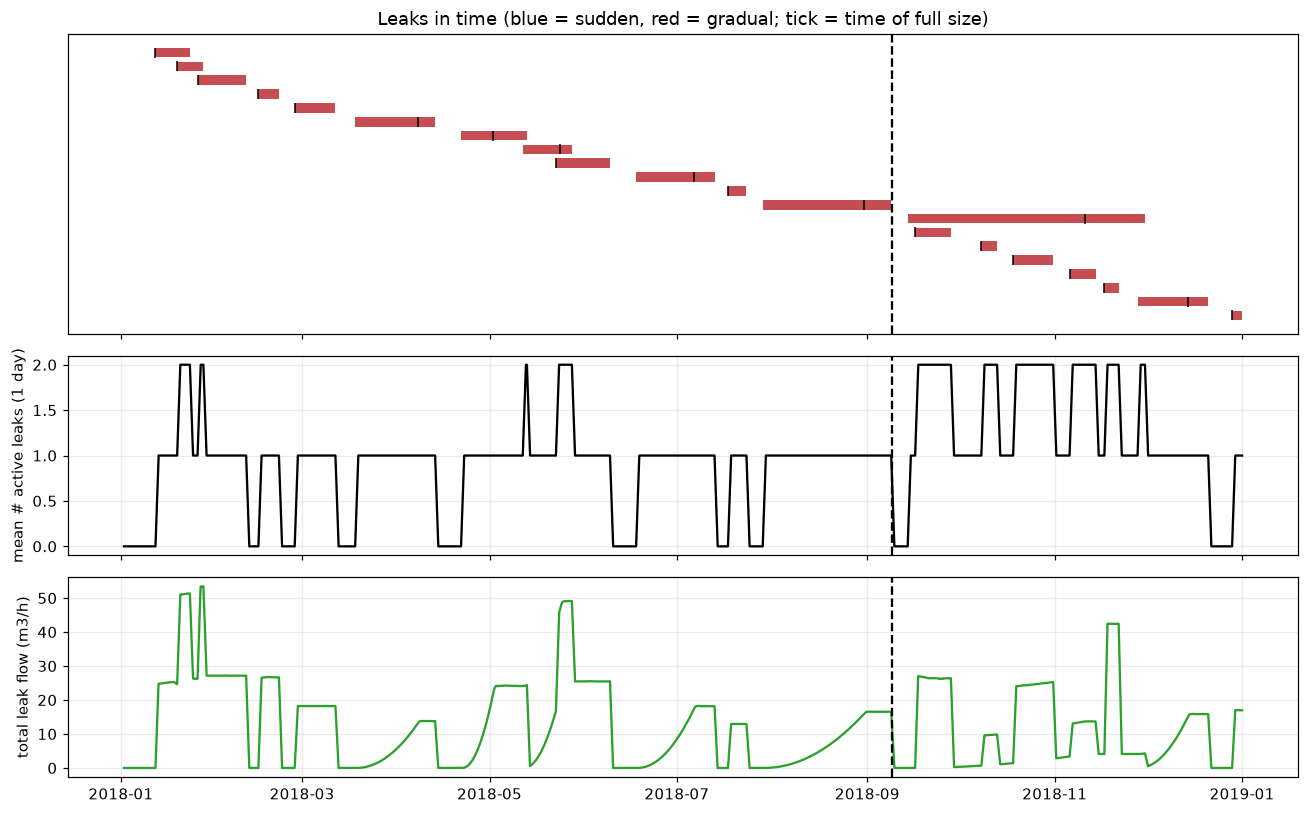

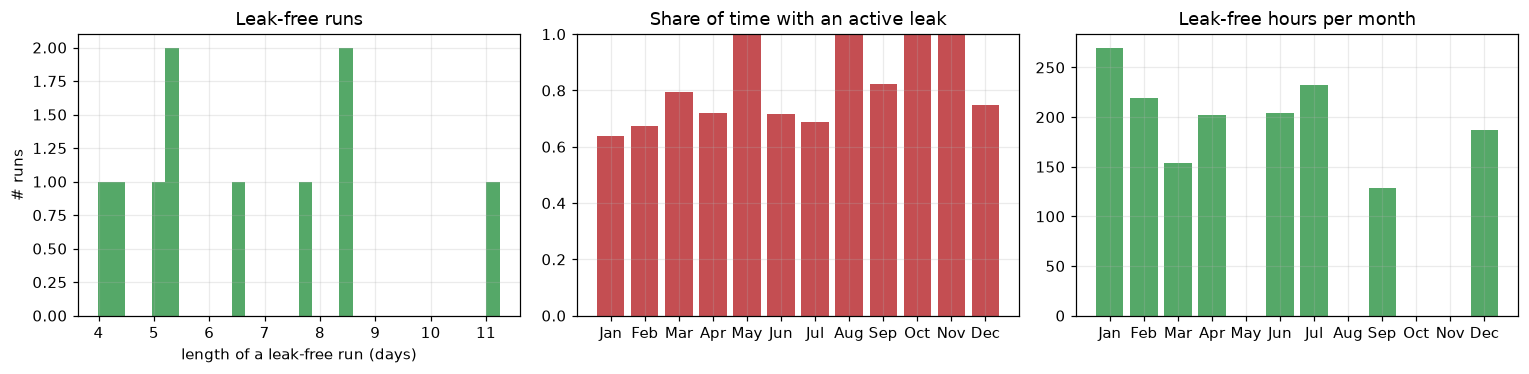

months with fewer than 48 leak-free hours: ['May', 'Aug', 'Oct', 'Nov']


/tmp/ipykernel_299320/523592882.py:51: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(lk[[c for c in ['leak_id', 'pipe_id', 'type', 'D_cm', peak_col, 'start', 'peak', 'end', 'duration_d', 'ramp_d', 'split'] if c]].round(2))


,leak_id,pipe_id,type,D_cm,peak_flow_m3h,start,peak,end,duration_d,ramp_d,split
0,L01,p262,abrupt,2.27,25.50,2018-01-12 06:00:00,2018-01-12 06:00:00,2018-01-23 10:50:00,11.20,0.00,train
1,L02,p420,abrupt,2.06,26.61,2018-01-19 07:20:00,2018-01-19 07:20:00,2018-01-27 20:20:00,8.54,0.00,train
2,L03,p446,abrupt,2.04,27.31,2018-01-25 22:45:00,2018-01-25 22:45:00,2018-02-10 18:15:00,15.81,0.00,train
3,L04,p323,abrupt,2.18,27.13,2018-02-14 18:10:00,2018-02-14 18:10:00,2018-02-21 10:25:00,6.68,0.00,train
4,L05,p75,abrupt,1.79,18.22,2018-02-26 13:45:00,2018-02-26 13:45:00,2018-03-11 20:00:00,13.26,0.00,train
5,L06,p732,incipient,1.45,13.92,2018-03-18 06:05:00,2018-04-07 15:45:00,2018-04-13 06:55:00,26.03,20.40,train
6,L07,p382,incipient,2.09,24.62,2018-04-21 17:25:00,2018-05-02 04:50:00,2018-05-13 04:05:00,21.44,10.48,train
7,L08,p835,incipient,1.97,23.90,2018-05-11 19:40:00,2018-05-24 02:05:00,2018-05-27 19:20:00,15.99,12.27,train
8,L09,p859,abrupt,1.98,25.75,2018-05-22 14:55:00,2018-05-22 14:55:00,2018-06-09 05:10:00,17.59,0.00,train
9,L10,p9,incipient,1.75,18.55,2018-06-17 17:25:00,2018-07-06 11:30:00,2018-07-13 05:50:00,25.52,18.75,train


            n  D_min  D_max  mean_ramp_days
type                                       
abrupt     13   1.23   2.37            0.00
incipient   7   0.85   2.09           24.13


In [3]:
leak = lab['leak_active'].values.astype(bool)
n_act = lab['n_active'].values
print('leak_active == (n_active > 0):', bool((leak == (n_act > 0)).all()),
      '| total_leak_m3h == sum of leak_flows:', bool(np.allclose(lab['total_leak_m3h'].values, LF.sum(axis=1).values, atol=1e-6)))
share_leak, share_ovl = leak.mean(), (n_act >= 2).mean()
print(f'time with >=1 active leak: {share_leak:.1%} | with >=2 overlapping: {share_ovl:.1%} | leak-free: {1 - share_leak:.1%}')
print('n_active distribution (%):', (100 * pd.Series(n_act).value_counts(normalize=True).sort_index()).round(1).to_dict())
SUMMARY.update(share_leak=float(share_leak), share_overlap=float(share_ovl))


def runs(mask):
    d = np.diff(np.concatenate([[0], np.asarray(mask, int), [0]]))
    return np.flatnonzero(d == 1), np.flatnonzero(d == -1)


free = ~leak
s, e = runs(free)
free_len_d = (e - s) / (STEP * 24)
tr_mask = np.asarray(lab.index < TRAIN_END)
st_, en_ = runs(free & tr_mask)
tab = pd.DataFrame([dict(min_length_h=h, runs_all=int(((e - s) >= h * STEP).sum()), hours_all=float(((e - s)[(e - s) >= h * STEP]).sum() / STEP),
                         runs_before_TRAIN_END=int(((en_ - st_) >= h * STEP).sum())) for h in (6, 24, 48, 72)])
display(tab)
SUMMARY.update(free_hours_total=float(free.sum() / STEP), free_runs_ge_48h=int(((e - s) >= 48 * STEP).sum()),
               free_runs_ge_72h_before_split=int(((en_ - st_) >= 72 * STEP).sum()))

fig, ax = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={'height_ratios': [1.5, 1, 1]})
for i, r in leaks.sort_values('start').reset_index(drop=True).iterrows():
    ax[0].barh(i, (r['end'] - r['start']).total_seconds() / 86400, left=mdates.date2num(r['start']), height=.7, color='#C44E52' if r['type'] != 'sudden' else '#4C72B0')
    ax[0].plot(mdates.date2num(r['peak']), i, 'k|')
ax[0].invert_yaxis(); ax[0].set_yticks([]); ax[0].set_title('Leaks in time (blue = sudden, red = gradual; tick = time of full size)'); ax[0].grid(False)
ax[1].plot(lab.index, pd.Series(n_act, index=lab.index).rolling(STEP * 24).mean(), color='k'); ax[1].set_ylabel('mean # active leaks (1 day)')
ax[2].plot(lab.index, lab['total_leak_m3h'].rolling(STEP * 24).mean(), color='tab:green'); ax[2].set_ylabel('total leak flow (m3/h)')
ax[2].axvline(TRAIN_END, color='k', ls='--'); ax[1].axvline(TRAIN_END, color='k', ls='--'); ax[0].axvline(mdates.date2num(TRAIN_END), color='k', ls='--')
ax[0].xaxis_date(); plt.tight_layout(); savefig('p0_leaks_timeline'); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(free_len_d, bins=30, color='#55A868'); ax[0].set_xlabel('length of a leak-free run (days)'); ax[0].set_ylabel('# runs'); ax[0].set_title('Leak-free runs')
mo = pd.DataFrame({'leak_share': pd.Series(leak, index=lab.index).resample('MS').mean(), 'free_hours': pd.Series(free, index=lab.index).resample('MS').sum() / STEP})
ax[1].bar(mo.index.strftime('%b'), mo['leak_share'], color='#C44E52'); ax[1].set_title('Share of time with an active leak'); ax[1].set_ylim(0, 1)
ax[2].bar(mo.index.strftime('%b'), mo['free_hours'], color='#55A868'); ax[2].set_title('Leak-free hours per month')
plt.tight_layout(); savefig('p0_labels_overview'); plt.show()
print('months with fewer than 48 leak-free hours:', list(mo.index[mo['free_hours'] < 48].strftime('%b')))

peak_col = next((c for c in leaks.columns if 'flow' in c.lower() or 'm3h' in c.lower()), None)
lk = leaks.copy()
lk['duration_d'] = (lk['end'] - lk['start']).dt.total_seconds() / 86400
lk['ramp_d'] = (lk['peak'] - lk['start']).dt.total_seconds() / 86400
lk['D_cm'] = lk['diameter_m'] * 100
lk['split'] = np.where(lk['start'] < TRAIN_END, 'train', 'validation')
display(lk[[c for c in ['leak_id', 'pipe_id', 'type', 'D_cm', peak_col, 'start', 'peak', 'end', 'duration_d', 'ramp_d', 'split'] if c]].round(2))
print(lk.groupby('type').agg(n=('D_cm', 'size'), D_min=('D_cm', 'min'), D_max=('D_cm', 'max'), mean_ramp_days=('ramp_d', 'mean')).round(2))

<div dir="rtl" style="text-align:right">

**چطور بخوانیم و چه تصمیمی بگیریم:**

- **برچسب:** اگر حدود ۸۰٪ گام‌ها نشت‌دارند، «نامتوازن» در اینجا یعنی کلاس عادی (بدون نشت) نادر است و هشدار کاذب روی آن اندازه‌گیری می‌شود. وزن‌دهی کلاس باید بر اساس سهم واقعی هر کلاس در آموزش باشد و نه فرض معمول «نشت نادر است».
- **بازه‌های بدون نشت:** رفتار عادی و نشت مصنوعی فقط از همین بازه‌ها می‌آید. اگر بازه‌ای بلندتر از ۴۸ ساعت کم داریم، طول قطعه مصنوعی و تعداد نمونه‌ها محدود می‌شود؛ و اگر ماه‌هایی ساعت بدون نشت کافی ندارند، خط پایه ثابت آن ماه‌ها قابل اعتماد نیست.
- **همپوشانی:** برچسب خوشه برای گام‌های با دو نشت باید روشن تعریف شود (مثلاً نشت غالب بر اساس جریان). تعداد این گام‌ها را از `n_active` بخوانید.
- **نشت‌های تدریجی:** ساعت‌های اول عملاً سیگنال ندارند؛ برچسب `leak_active` همان ساعت‌ها را مثبت می‌گیرد. این منبع اصلی «تأخیر» در آشکارسازی است و باید در تحلیل خطا بیاید.

</div>

<div dir="rtl" style="text-align:right">

## ۳. رفتار عادی فشار و ساختار نویز

ابتدا بدانیم فشار در ساعت‌های بدون نشت چقدر قابل پیش‌بینی است: چرخه روزانه، تفاوت آخر هفته، رانش ماهانه. این تعیین می‌کند «خط پایه» چقدر باید پیچیده باشد. سپس باقیمانده بعد از حذف خط پایه را به‌عنوان **نویز** بررسی می‌کنیم: ساختار همبستگی بین حسگرها (آیا چند جهت مشترک غالب است؟) و خودهمبستگی زمانی (چرا تفکیک تصادفی داده را نشت می‌دهد؟).

</div>

variance of leak-free hourly pressure explained by a fixed baseline (mean over sensors): {'hour of day': np.float64(0.68), 'hour x weekend': np.float64(0.718)}


/tmp/ipykernel_299320/329662495.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  hour, wkend, month = Ph.index.hour.values, (Ph.index.dayofweek >= 5).astype(int), Ph.index.month.values
/tmp/ipykernel_299320/329662495.py:22: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  wk = Ph[free_h].groupby(Ph.index.dayofweek[free_h]).mean(); wk = wk - wk.mean()


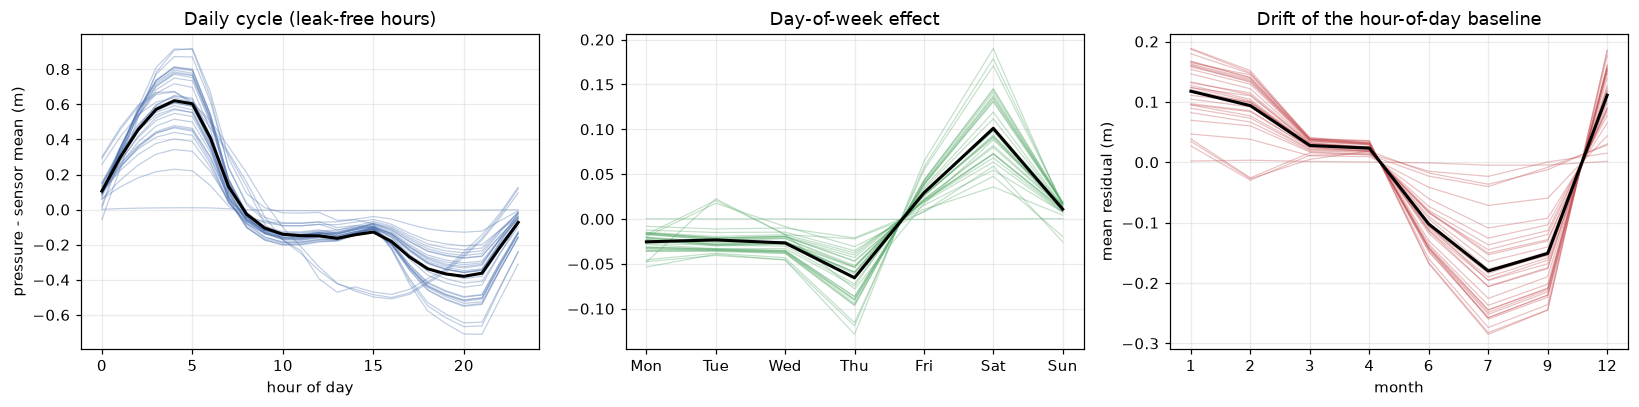

largest monthly deviation of a sensor from the yearly baseline: 0.27 m | leak-free hours per month: {1: 270, 2: 217, 3: 153, 4: 202, 5: 0, 6: 203, 7: 231, 8: 0, 9: 128, 10: 0, 11: 0, 12: 185}


In [4]:
Ph = P.resample('h').mean()
free_h = (pd.Series(leak, index=lab.index).resample('h').max() == 0).values            # whole hour leak-free
hour, wkend, month = Ph.index.hour.values, (Ph.index.dayofweek >= 5).astype(int), Ph.index.month.values


def hod_baseline(key):
    """mean of leak-free hours per key; returns a baseline with the same index as Ph"""
    k = pd.Series(key, index=Ph.index)
    g = Ph[free_h].groupby(k[free_h].values).mean()
    return g.reindex(k.values).set_axis(Ph.index)


b_hod, b_how = hod_baseline(hour), hod_baseline(hour * 2 + wkend)
tot_var = Ph[free_h].var().mean()
r2 = {'hour of day': 1 - (Ph - b_hod)[free_h].var().mean() / tot_var, 'hour x weekend': 1 - (Ph - b_how)[free_h].var().mean() / tot_var}
print('variance of leak-free hourly pressure explained by a fixed baseline (mean over sensors):', {k: round(v, 3) for k, v in r2.items()})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
prof = Ph[free_h].groupby(hour[free_h]).mean(); prof = prof - prof.mean()
ax[0].plot(prof.values, color='#4C72B0', alpha=.35, lw=.8); ax[0].plot(prof.mean(axis=1).values, 'k', lw=2)
ax[0].set_xlabel('hour of day'); ax[0].set_ylabel('pressure - sensor mean (m)'); ax[0].set_title('Daily cycle (leak-free hours)')
wk = Ph[free_h].groupby(Ph.index.dayofweek[free_h]).mean(); wk = wk - wk.mean()
ax[1].plot(wk.values, color='#55A868', alpha=.35, lw=.8); ax[1].plot(wk.mean(axis=1).values, 'k', lw=2)
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']); ax[1].set_title('Day-of-week effect')
res_h = (Ph - b_hod)
mon = res_h[free_h].groupby(month[free_h]).mean()
ax[2].plot(mon.values, color='#C44E52', alpha=.35, lw=.8); ax[2].plot(mon.mean(axis=1).values, 'k', lw=2)
ax[2].set_xticks(range(len(mon))); ax[2].set_xticklabels(mon.index); ax[2].set_xlabel('month'); ax[2].set_ylabel('mean residual (m)'); ax[2].set_title('Drift of the hour-of-day baseline')
plt.tight_layout(); savefig('p0_normal_behaviour'); plt.show()
drift = float((mon - mon.mean()).abs().values.max())
cnt = pd.Series(free_h).groupby(month).sum()
print(f'largest monthly deviation of a sensor from the yearly baseline: {drift:.2f} m | leak-free hours per month:', cnt.to_dict())
SUMMARY.update(r2_hour_of_day=float(r2['hour of day']), r2_hour_weekend=float(r2['hour x weekend']), max_monthly_drift_m=drift)

noise variance share of the top 1 / 2 / 5 principal directions: 0.87 / 0.98 / 1.00
autocorrelation of the dominant noise direction (PC1): {'5 min': np.float64(0.893), '1 h': np.float64(0.792), '6 h': np.float64(0.335), '24 h': np.float64(0.6)}
under a RANDOM 70/30 split, 70% of validation steps have their previous 5-min step in the training set (neighbour correlation ~ 0.89) -> information leaks; a time/event split has only the boundary


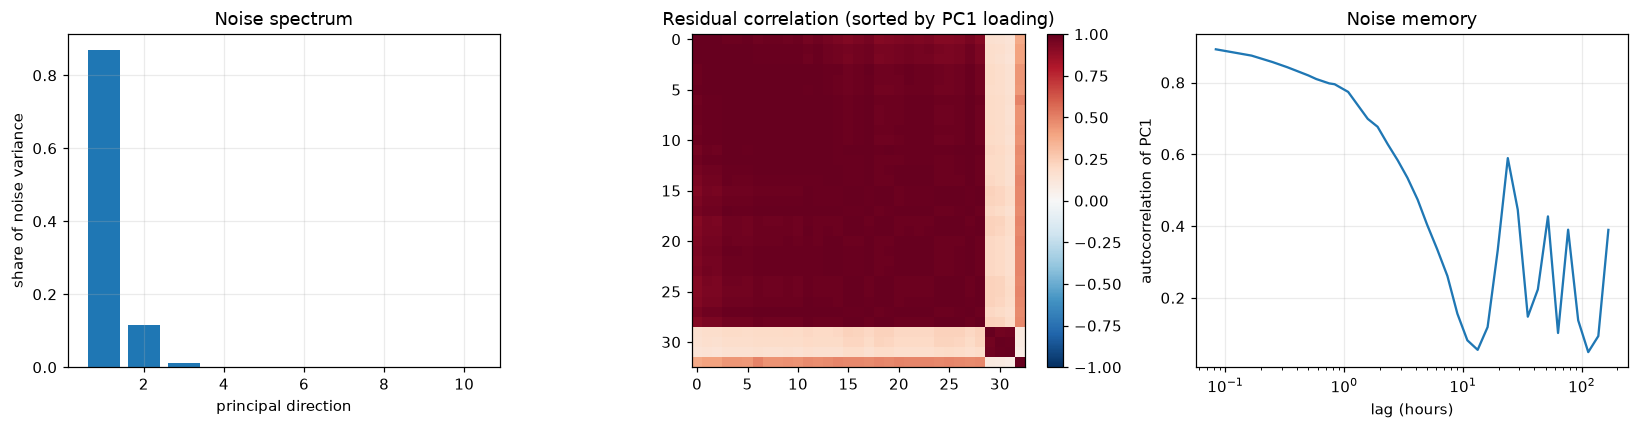

In [5]:
# ---- noise: residual of leak-free 5-minute data after the hour-of-day baseline
R5 = P - b_hod.reindex(P.index.floor('h')).set_axis(P.index)        # hour-of-day baseline (leak-free means) applied to 5-min data
R5f = R5[free]
cov = np.cov(R5f.dropna().values.T)
w, V = np.linalg.eigh(cov); w, V = w[::-1], V[:, ::-1]
share = w / w.sum()
print(f'noise variance share of the top 1 / 2 / 5 principal directions: {share[0]:.2f} / {share[:2].sum():.2f} / {share[:5].sum():.2f}')

pc1 = pd.Series(np.nan, index=P.index); pc1[free] = (R5[free].values - R5f.mean().values) @ V[:, 0]
ac = {'5 min': pc1.autocorr(1), '1 h': pc1.autocorr(STEP), '6 h': pc1.autocorr(6 * STEP), '24 h': pc1.autocorr(24 * STEP)}
print('autocorrelation of the dominant noise direction (PC1):', {k: round(v, 3) for k, v in ac.items()})
rng = np.random.default_rng(0)
m_tr = np.asarray(lab.index < TRAIN_END)
rand_val = rng.random(len(P)) < 0.3
print(f'under a RANDOM 70/30 split, {np.mean(~np.roll(rand_val, 1)[rand_val]):.0%} of validation steps have their previous 5-min step in the training set '
      f'(neighbour correlation ~ {ac["5 min"]:.2f}) -> information leaks; a time/event split has only the boundary')
SUMMARY.update(noise_top2_share=float(share[:2].sum()), noise_pc1_acf_5min=float(ac['5 min']), noise_pc1_acf_24h=float(ac['24 h']))

order = np.argsort(V[:, 0])
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].bar(range(1, 11), share[:10]); ax[0].set_xlabel('principal direction'); ax[0].set_ylabel('share of noise variance'); ax[0].set_title('Noise spectrum')
im = ax[1].imshow(np.corrcoef(R5f.dropna().values.T)[np.ix_(order, order)], cmap='RdBu_r', vmin=-1, vmax=1); ax[1].grid(False)
ax[1].set_title('Residual correlation (sorted by PC1 loading)'); plt.colorbar(im, ax=ax[1], fraction=.04)
lags = np.unique(np.round(np.geomspace(1, 7 * 24 * STEP, 40)).astype(int))
ax[2].semilogx(lags / STEP, [pc1.autocorr(int(l)) for l in lags]); ax[2].set_xlabel('lag (hours)'); ax[2].set_ylabel('autocorrelation of PC1'); ax[2].set_title('Noise memory')
plt.tight_layout(); savefig('p0_noise_structure'); plt.show()

<div dir="rtl" style="text-align:right">

**چطور بخوانیم و چه تصمیمی بگیریم:**

- **خط پایه:** اگر «ساعت روز» بخش بزرگی از واریانس را می‌گیرد و افزودن آخر هفته چیز مهمی اضافه نمی‌کند، خط پایه ساده کافی است. اگر رانش ماهانه چند برابر اثر نشت‌های کوچک (چند ده سانتی‌متر) است، خط پایه ثابت یک‌ساله خطرناک است و باید یا به‌روز شود یا از اختلاف پنجره کوتاه با پنجره بلند استفاده شود.
- **نویز:** اگر یک یا دو جهت اصلی بخش عمده نویز را می‌سازند (حرکت مشترک همه حسگرها، مثلاً اثر تراز مخزن)، سفیدسازی منطقی است و مقایسه خام اقلیدسی را آن جهت‌ها تحت‌الشعاع قرار می‌دهند؛ همان استدلال بخش ۱.
- **خودهمبستگی:** همبستگی بسیار بالای گام‌های مجاور یعنی تفکیک تصادفی به معنی آزمودن روی داده‌ای است که نمونه‌های همسایه‌اش در آموزش بوده. اعداد بالا را در بخش «قاعده تفکیک» گزارش بیاورید. حافظه نویز همچنین طول مفید پنجره را محدود می‌کند: پنجره‌ای کوتاه‌تر از حافظه نویز، نویز را میانگین‌گیری نمی‌کند.

</div>

<div dir="rtl" style="text-align:right">

## ۴. جریان، تراز مخزن و AMR

سه سؤال: (۱) جریان ورودی چقدر از تقاضای AMR قابل پیش‌بینی است؟ (اگر زیاد باشد، اختلاف آن‌ها شاخص نشت است.) (۲) تراز مخزن چرخه روزانه‌ای دارد که فشار حسگرها را هم جابه‌جا می‌کند؟ (۳) **سهم هر حسگر جریان از افزایش ورودی** در اثر نشت چقدر است؟ این همان ثابت `FLOW_SHARE = [0.05, 0.475, 0.475]` در `clusters.py` است که فقط یک حدس بود؛ این‌جا از داده واقعی برآوردش می‌کنیم.

**روش:** روی ساعت‌های کاملاً بدون نشت، هر جریان را با رگرسیون روی تقاضای کل AMR و ساعت روز مدل می‌کنیم؛ سپس باقیمانده جریان را در ساعت‌های نشت‌دار روی `total_leak_m3h` رگرسیون می‌کنیم (از مبدأ). شیب هر منبع، سهم آن منبع از نشت است.

</div>

correlation of total inflow with total AMR demand (leak-free hours): 0.470


,source,mean_flow_m3h,baseline_R2_leak_free,slope_on_leak_flow,share_of_sum
0,PUMP_1,21.098,0.538,0.159,0.127
1,p227,92.327,0.843,0.569,0.454
2,p235,96.057,0.829,0.527,0.420


sum of slopes = 1.26 (1.0 would mean the inflow carries the whole leak flow)
estimated FLOW_SHARE = [0.127, 0.454, 0.42]  | value used in clusters.py: [0.05, 0.475, 0.475]


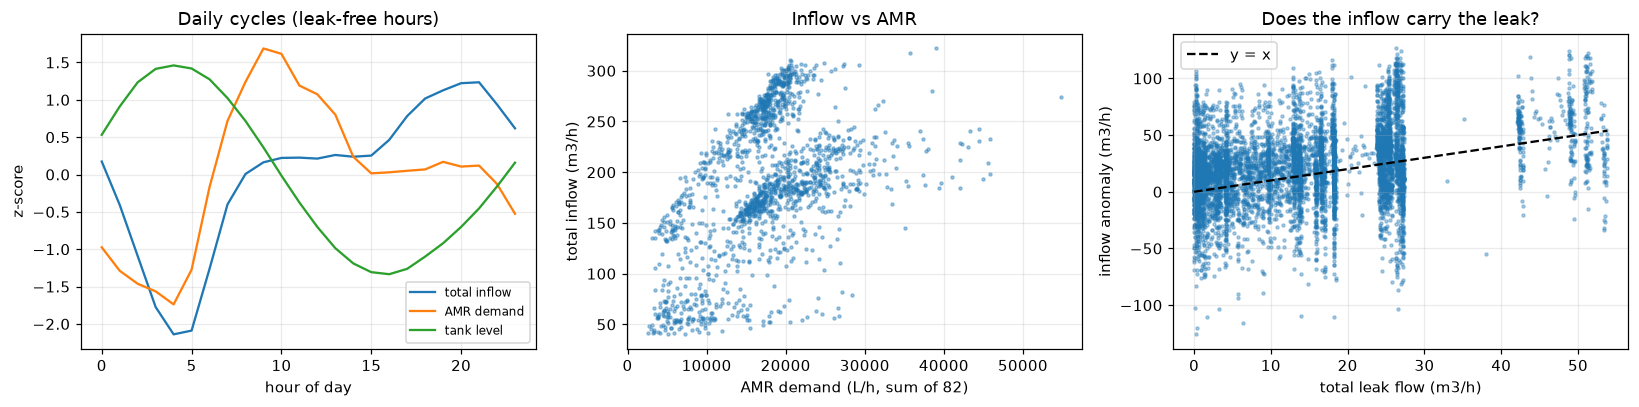

In [6]:
Fh = Fl.resample('h').mean(); Ah = Dm.sum(axis=1).resample('h').mean(); Lh_ = Lv.iloc[:, 0].resample('h').mean()
leak_h = lab['total_leak_m3h'].resample('h').mean().values
act_h = lab['leak_active'].resample('h').max().values == 1
tot_in = Fh.sum(axis=1)
print('correlation of total inflow with total AMR demand (leak-free hours): %.3f' % np.corrcoef(tot_in[free_h], Ah[free_h])[0, 1])

X = np.column_stack([np.ones(len(Ah)), Ah.values] + [(hour == h).astype(float) for h in range(1, 24)])
rows, resid = [], {}
for c in Fh.columns:
    beta, *_ = np.linalg.lstsq(X[free_h], Fh[c].values[free_h], rcond=None)
    r = Fh[c].values - X @ beta
    resid[c] = r
    r2c = 1 - r[free_h].var() / Fh[c].values[free_h].var()
    sl = float(r[act_h] @ leak_h[act_h] / (leak_h[act_h] @ leak_h[act_h]))
    rows.append(dict(source=c, mean_flow_m3h=Fh[c].mean(), baseline_R2_leak_free=r2c, slope_on_leak_flow=sl))
fs = pd.DataFrame(rows)
fs['share_of_sum'] = fs['slope_on_leak_flow'] / fs['slope_on_leak_flow'].sum()
display(fs.round(3))
print(f"sum of slopes = {fs['slope_on_leak_flow'].sum():.2f} (1.0 would mean the inflow carries the whole leak flow)")
print('estimated FLOW_SHARE =', fs['share_of_sum'].round(3).tolist(), ' | value used in clusters.py: [0.05, 0.475, 0.475]')
SUMMARY.update(flow_share_est=fs['share_of_sum'].round(4).tolist(), flow_slope_sum=float(fs['slope_on_leak_flow'].sum()), corr_inflow_amr=float(np.corrcoef(tot_in[free_h], Ah[free_h])[0, 1]))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sc_ = lambda s: (s - s.mean()) / s.std()
for nm, s in (('total inflow', tot_in), ('AMR demand', Ah), ('tank level', Lh_)):
    ax[0].plot(sc_(s[free_h].groupby(hour[free_h]).mean()).values, label=nm)
ax[0].set_xlabel('hour of day'); ax[0].set_ylabel('z-score'); ax[0].legend(fontsize=8); ax[0].set_title('Daily cycles (leak-free hours)')
ax[1].scatter(Ah[free_h], tot_in[free_h], s=4, alpha=.4); ax[1].set_xlabel('AMR demand (L/h, sum of 82)'); ax[1].set_ylabel('total inflow (m3/h)'); ax[1].set_title('Inflow vs AMR')
tot_res = sum(resid.values())
ax[2].scatter(leak_h[act_h], tot_res[act_h], s=4, alpha=.35); lim = [0, np.nanmax(leak_h)]
ax[2].plot(lim, lim, 'k--', label='y = x'); ax[2].set_xlabel('total leak flow (m3/h)'); ax[2].set_ylabel('inflow anomaly (m3/h)'); ax[2].legend(); ax[2].set_title('Does the inflow carry the leak?')
plt.tight_layout(); savefig('p0_flows_amr'); plt.show()

<div dir="rtl" style="text-align:right">

**چطور بخوانیم:** (۱) اگر مجموع شیب‌ها نزدیک ۱ است، افزایش جریان ورودی تقریباً همه جریان نشت را نشان می‌دهد و اضافه کردن جریان‌ها به ورودی آشکارساز منطقی است؛ اگر خیلی کمتر است، نشت بخشی از خود را با افت تقاضا (فشار کمتر) جبران می‌کند. (۲) اگر سهم‌های برآوردشده با `[0.05, 0.475, 0.475]` فرق محسوس دارند، آن ثابت را در `clusters.py` و `run_part2_localiser.py` (`pl.FLOW_SHARE`) اصلاح کنید و خوشه‌ها را دوباره بسازید؛ در غیر این صورت می‌توانید بنویسید حدس اولیه با داده سازگار بود. (۳) `baseline_R2_leak_free` پایین یعنی جریان را فقط از AMR و ساعت نمی‌توان پیش‌بینی کرد (AMR فقط ۸۲ خانوار است)؛ پس استفاده از AMR به‌عنوان ورودی سودمند ولی محدود است.

</div>

<div dir="rtl" style="text-align:right">

## ۵. اثر نشت در داده واقعی

برای هر نشت، **تغییر اندازه‌گیری‌شده** را همان‌طور که شرح پروژه می‌گوید می‌سازیم: میانگین باقیمانده فشار (نسبت به خط پایه ساعت روز) در بازه اندازه کامل نشت، منهای میانگین باقیمانده در ساعت‌های بدون نشت پیرامون (±۱۵ روز؛ اگر کمتر از ۲۴ ساعت بدون نشت باشد، پنجره تا ±۱۲۰ روز بزرگ می‌شود و `ref_window_days` گزارش می‌شود). فقط ساعت‌هایی که **همان یک نشت** فعال است (`n_active == 1`) به‌کار می‌روند تا نشت‌های همپوشان نتیجه را آلوده نکنند. سپس اندازه آن را با قطر مقایسه می‌کنیم: اگر مدل «اثر ∝ مساحت روزنه $D^2$» درست باشد، نمودار log-log باید شیب حدود ۱ در $D^2$ داشته باشد.

</div>

,leak,D_cm,hours_alone,ref_window_days,free_hours_ref,norm_m,max_sensor,max_change_m
0,L01,2.266,169,15,270,1.617,n1,-0.839
1,L02,2.058,59,15,190,1.826,n54,-0.541
2,L03,2.038,334,15,31,0.713,n469,-0.311
3,L04,2.180,160,15,217,1.589,n410,-0.871
4,L05,1.793,318,15,239,1.165,n229,-0.662
5,L06,1.451,135,15,202,0.853,n644,-0.248
6,L07,2.087,230,15,108,1.688,n429,-0.545
7,L08,1.969,0,30,203,NaN,NaN,NaN
8,L09,1.978,298,30,203,1.487,n752,-0.823
9,L10,1.752,162,15,105,1.278,n54,-0.423


log-log slope of ||change|| vs D: 1.00  (area law predicts about 2; scatter comes from the pipe location)


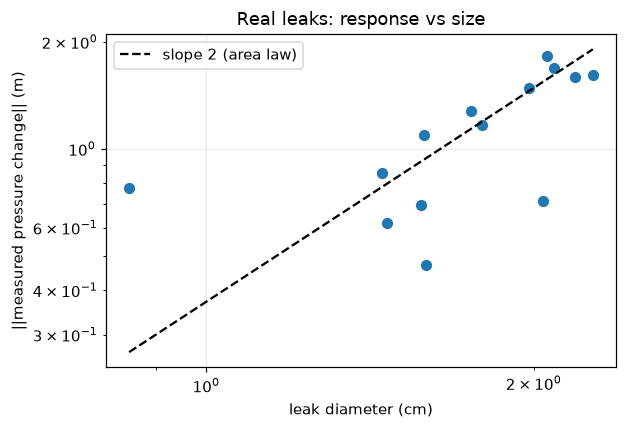

In [7]:
res_h = Ph - b_hod                                              # hourly residual vs hour-of-day baseline
nact_h = pd.Series(n_act, index=lab.index).resample('h').max().values
rows, meas = [], {}
for i, r in leaks.reset_index(drop=True).iterrows():
    win = (Ph.index >= r['peak']) & (Ph.index < r['end']) & (nact_h == 1)
    dist = np.abs((Ph.index - r['peak']).total_seconds())
    for half in (15, 30, 60, 120):                                  # widen the reference window until it has >= 24 leak-free hours
        around = free_h & (dist <= half * 86400)
        if around.sum() >= 24: break
    base_info = dict(leak=r.get('leak_id', i), D_cm=r['diameter_m'] * 100, hours_alone=int(win.sum()), ref_window_days=half, free_hours_ref=int(around.sum()))
    if win.sum() < 6 or around.sum() < 24:
        rows.append(dict(base_info, norm_m=np.nan)); continue
    m = res_h[win].mean() - res_h[around].mean()
    meas[i] = m.values
    rows.append(dict(base_info, norm_m=float(np.linalg.norm(m.values)), max_sensor=m.abs().idxmax(), max_change_m=float(m[m.abs().idxmax()])))
resp = pd.DataFrame(rows)
display(resp.round(3))
ok = resp['norm_m'].notna() & (resp['norm_m'] > 0)
if ok.sum() >= 4:
    x, yv = np.log(resp.loc[ok, 'D_cm']), np.log(resp.loc[ok, 'norm_m'])
    slope = np.polyfit(x, yv, 1)[0]
    print(f'log-log slope of ||change|| vs D: {slope:.2f}  (area law predicts about 2; scatter comes from the pipe location)')
    SUMMARY['loglog_slope_norm_vs_D'] = float(slope)
    fig, ax = plt.subplots(figsize=(5.8, 4))
    ax.scatter(resp.loc[ok, 'D_cm'], resp.loc[ok, 'norm_m'], s=40)
    xs = np.linspace(resp.loc[ok, 'D_cm'].min(), resp.loc[ok, 'D_cm'].max(), 50)
    ax.plot(xs, np.exp(np.median(yv - 2 * x)) * xs ** 2, 'k--', label='slope 2 (area law)')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('leak diameter (cm)'); ax.set_ylabel('||measured pressure change|| (m)'); ax.legend(); ax.set_title('Real leaks: response vs size')
    plt.tight_layout(); savefig('p0_response_vs_size'); plt.show()

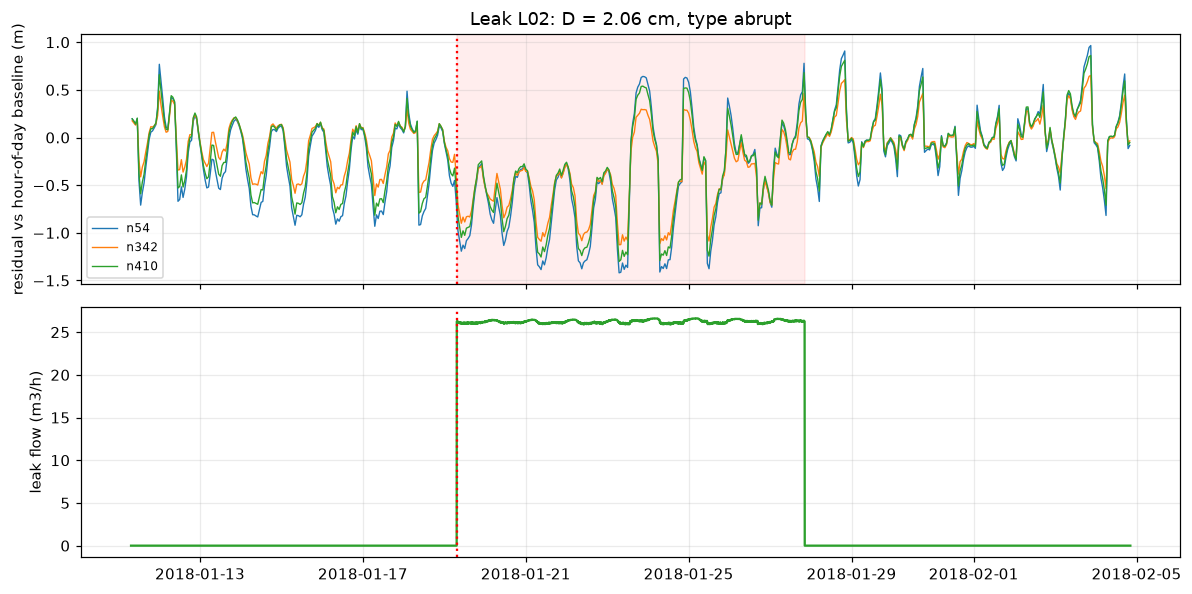

          days_to_30pct        days_to_90pct       
                   mean    max          mean    max
type                                               
abrupt             0.00   0.00           0.0   0.00
incipient         13.23  31.47          23.0  54.58


In [8]:
# ---- one picture of a large leak: the 3 most affected sensors and the leak flow
assert resp['norm_m'].notna().any(), 'no leak had enough single-leak hours and leak-free reference hours'
j = resp['norm_m'].idxmax()
r = leaks.reset_index(drop=True).loc[j]
sens = pd.Series(meas[j], index=P.columns).abs().nlargest(3).index
t0, t1 = r['start'] - pd.Timedelta(days=8), r['end'] + pd.Timedelta(days=8)
sl = (Ph.index >= t0) & (Ph.index <= t1)
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for c in sens:
    ax[0].plot(Ph.index[sl], res_h.loc[sl, c], label=c, lw=.9)
ax[0].axvspan(r['start'], r['end'], color='red', alpha=.07); ax[0].axvline(r['peak'], color='r', ls=':')
ax[0].set_ylabel('residual vs hour-of-day baseline (m)'); ax[0].legend(fontsize=8); ax[0].set_title(f"Leak {r.get('leak_id', j)}: D = {r['diameter_m'] * 100:.2f} cm, type {r['type']}")
col = str(r.get('leak_id', j)) if str(r.get('leak_id', j)) in LF.columns else LF.columns[j]
ax[1].plot(LF.index[(LF.index >= t0) & (LF.index <= t1)], LF.loc[(LF.index >= t0) & (LF.index <= t1), col], color='tab:green')
ax[1].set_ylabel('leak flow (m3/h)'); ax[1].axvline(r['peak'], color='r', ls=':')
plt.tight_layout(); savefig('p0_example_leak'); plt.show()

# ---- ramp shape: how long does a gradual leak need to reach 30% / 90% of its peak flow?
rows = []
for i, r in leaks.reset_index(drop=True).iterrows():
    col = str(r.get('leak_id', i)) if str(r.get('leak_id', i)) in LF.columns else LF.columns[i]
    f = LF[col].loc[r['start']:r['end']]
    if f.max() <= 0: continue
    fr = f / f.max()
    rows.append(dict(leak=r.get('leak_id', i), type=r['type'], D_cm=r['diameter_m'] * 100,
                     days_to_30pct=(fr.index[(fr >= .3).values.argmax()] - r['start']).total_seconds() / 86400,
                     days_to_90pct=(fr.index[(fr >= .9).values.argmax()] - r['start']).total_seconds() / 86400))
ramp = pd.DataFrame(rows)
print(ramp.groupby('type')[['days_to_30pct', 'days_to_90pct']].agg(['mean', 'max']).round(2))
SUMMARY['gradual_days_to_30pct_max'] = float(ramp.loc[ramp['type'] != 'sudden', 'days_to_30pct'].max()) if (ramp['type'] != 'sudden').any() else None

<div dir="rtl" style="text-align:right">

**چطور بخوانیم و چه تصمیمی بگیریم:**

- **قانون مساحت:** اگر شیب log-log به ۲ نزدیک است، فرض «امضای مدل در $(D/1.5)^2$ ضرب می‌شود» (بخش ۱) روی داده واقعی هم خوب است. شیب‌های خیلی متفاوت یعنی محل لوله اثر غالب دارد و نمودار فقط با تعداد کم نشت نمی‌توان قاطعانه تفسیر کرد.
- **نشت‌های کوچک:** نشتی که تغییر اندازه‌گیری‌شده‌اش از نویز ساعتی (بخش ۳) کوچک‌تر است، با این پنجره‌ها تقریباً غیرقابل تشخیص است. اندازه نویز ساعتی را با ستون `max_change_m` مقایسه کنید؛ این سقف واقع‌بینانه «تعداد تشخیص» است.
- **زمان رشد:** `days_to_30pct` برای نشت‌های تدریجی نشان می‌دهد چند روز طول می‌کشد تا نشت به آستانه قابل مشاهده برسد. این عدد حد پایین تأخیر قابل دستیابی است و برای گزارش «تأخیر» به‌عنوان مرجع به‌کار می‌رود. وزن‌دهی صفر روی ساعت‌های ابتدایی چنین نشت‌هایی (`dom_frac < 0.10`) با همین استدلال توجیه می‌شود.
- **خطای ساخت:** ساعت‌های همپوشان حذف شده‌اند. اگر برای نشتی کمتر از ۶ ساعت تنها مانده، نتیجه‌اش خالی است؛ این نشت‌ها را برای آزمون مدل هیدرولیکی (نوت‌بوک ۰۴) باید جدا بررسی کرد.

</div>

<div dir="rtl" style="text-align:right">

## ۶. خلاصه یافته‌ها برای گزارش

اعداد زیر در `artifacts/eda_summary.json` ذخیره می‌شوند و جمله‌های بخش «داده و پروتکل» گزارش از همین‌ها ساخته می‌شود.

</div>

In [9]:
json.dump(SUMMARY, open(ART / 'eda_summary.json', 'w'), indent=1)
g = lambda k, f='{:.2f}': (f.format(SUMMARY[k]) if SUMMARY.get(k) is not None else 'n/a')
text = f"""<div dir="rtl" style="text-align:right">

**خلاصه EDA**

- زمان دارای نشت: **{100 * SUMMARY['share_leak']:.0f}٪**، همپوشانی دو نشت: {100 * SUMMARY['share_overlap']:.0f}٪؛ ساعت بدون نشت کل سال: {SUMMARY['free_hours_total']:.0f} ساعت؛ بازه‌های بدون نشت ≥ ۴۸ ساعت: {SUMMARY['free_runs_ge_48h']}.
- ساعت روز {100 * SUMMARY['r2_hour_of_day']:.0f}٪ و ساعت×آخر هفته {100 * SUMMARY['r2_hour_weekend']:.0f}٪ واریانس فشار ساعات بدون نشت را توضیح می‌دهد؛ بیشینه رانش ماهانه {g('max_monthly_drift_m')} متر.
- دو جهت اصلی نویز {100 * SUMMARY['noise_top2_share']:.0f}٪ واریانس نویز را دارند؛ خودهمبستگی PC1: {g('noise_pc1_acf_5min')} (۵ دقیقه) و {g('noise_pc1_acf_24h')} (۲۴ ساعت).
- همبستگی جریان کل با AMR: {g('corr_inflow_amr')}؛ مجموع شیب‌های جریان روی نشت: {g('flow_slope_sum')}؛ سهم برآوردشده منابع: {SUMMARY['flow_share_est']}.
- شیب log-log اندازه اثر بر قطر: {g('loglog_slope_norm_vs_D')} (قانون مساحت: ۲).

</div>"""
display(Markdown(text))

<div dir="rtl" style="text-align:right">

**خلاصه EDA**

- زمان دارای نشت: **82٪**، همپوشانی دو نشت: 16٪؛ ساعت بدون نشت کل سال: 1597 ساعت؛ بازه‌های بدون نشت ≥ ۴۸ ساعت: 10.
- ساعت روز 68٪ و ساعت×آخر هفته 72٪ واریانس فشار ساعات بدون نشت را توضیح می‌دهد؛ بیشینه رانش ماهانه 0.27 متر.
- دو جهت اصلی نویز 98٪ واریانس نویز را دارند؛ خودهمبستگی PC1: 0.89 (۵ دقیقه) و 0.60 (۲۴ ساعت).
- همبستگی جریان کل با AMR: 0.47؛ مجموع شیب‌های جریان روی نشت: 1.26؛ سهم برآوردشده منابع: [0.1267, 0.4535, 0.4198].
- شیب log-log اندازه اثر بر قطر: 1.00 (قانون مساحت: ۲).

</div>

<div dir="rtl" style="text-align:right">

## ۷. جمع‌بندی: یافته ← تصمیم

| اگر در EDA دیدید… | تصمیم |
| --- | --- |
| حدود ۸۰٪ زمان نشت‌دار است | وزن‌دهی بر اساس سهم واقعی؛ گزارش هشدار کاذب فقط روی کلاس بدون نشت؛ آموزش آشکارساز روی داده نامتوازن با کلاس عادی نادر |
| بازه‌های بدون نشت ≥ ۴۸ ساعت کم یا ماه‌های بدون ساعت کافی | قطعه مصنوعی کوتاه‌تر؛ خط پایه فقط از ماه‌های دارای نمونه؛ نشت مصنوعی را فقط در آن بازه‌ها بگذارید |
| رانش ماهانه خط پایه بزرگ | خط پایه تطبیقی یا ورودی اختلاف پنجره کوتاه و بلند؛ بررسی هشدار کاذب در ماه‌های دور از آموزش |
| نویز در ۱ تا ۲ جهت متمرکز | سفیدسازی (و استفاده از اختلاف‌های سفیدشده برای مکان‌یاب) |
| خودهمبستگی بسیار بالای گام‌های مجاور | تفکیک زمانی یا بر اساس رخداد؛ یادداشت ریسک نشت در حاشیه مرز |
| مجموع شیب‌های جریان کمتر از ۱ | جریان‌ها سیگنال کمکی‌اند نه معیار مستقیم؛ `FLOW_SHARE` را با برآورد داده جایگزین کنید |
| شیب log-log نزدیک ۲ | استفاده از قانون مساحت برای ساخت نشت مصنوعی موجه است؛ در غیر این صورت ضریب را از نشت‌های واقعی کالیبره کنید |
| نشت‌های تدریجی با رشد چند روزه | تأخیر قابل دستیابی محدود است؛ وزن صفر برای ساعت‌های ابتدایی را در گزارش توجیه کنید |

</div>